In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from matplotlib.colors import ListedColormap

In [2]:
df = pd.read_csv('/content/mushroom.csv')
display(df.head())

,Unnamed: 0,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat,class,stalk_height,cap_diameter
0,1167,sunken,scaly,white,no,anise,descending,distant,broad,pink,...,partial,brown,two,sheathing,chocolate,clustered,waste,poisonous,14.276173,5.054983
1,1037,sunken,fibrous,red,no,anise,notched,crowded,narrow,chocolate,...,universal,brown,two,sheathing,brown,numerous,waste,edible,3.952715,19.068319
2,309,flat,grooves,purple,yes,foul,descending,crowded,broad,purple,...,universal,yellow,two,sheathing,purple,abundant,waste,poisonous,9.054265,7.205884
3,282,bell,scaly,pink,yes,fishy,notched,close,broad,orange,...,partial,yellow,two,cobwebby,green,clustered,grasses,poisonous,5.226499,20.932692
4,820,flat,smooth,yellow,yes,musty,free,crowded,narrow,orange,...,universal,white,none,none,yellow,clustered,urban,poisonous,14.037532,12.545245


### EDA

In [3]:
display(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                2000 non-null   int64  
 1   cap_shape                 2000 non-null   object 
 2   cap_surface               2000 non-null   object 
 3   cap_color                 2000 non-null   object 
 4   bruises                   2000 non-null   object 
 5   odor                      2000 non-null   object 
 6   gill_attachment           2000 non-null   object 
 7   gill_spacing              2000 non-null   object 
 8   gill_size                 2000 non-null   object 
 9   gill_color                2000 non-null   object 
 10  stalk_shape               2000 non-null   object 
 11  stalk_root                2000 non-null   object 
 12  stalk_surface_above_ring  2000 non-null   object 
 13  stalk_surface_below_ring  2000 non-null   object 
 14  stalk_co

None

,Unnamed: 0,stalk_height,cap_diameter
count,2000.000000,2000.000000,2000.000000
mean,624.974000,8.449118,12.314345
std,375.091938,3.697217,7.048845
min,0.000000,2.000000,1.000000
25%,290.000000,5.291009,5.723521
50%,607.000000,8.318596,12.124902
75%,957.250000,11.781272,18.698605
max,1279.000000,15.095066,25.000054


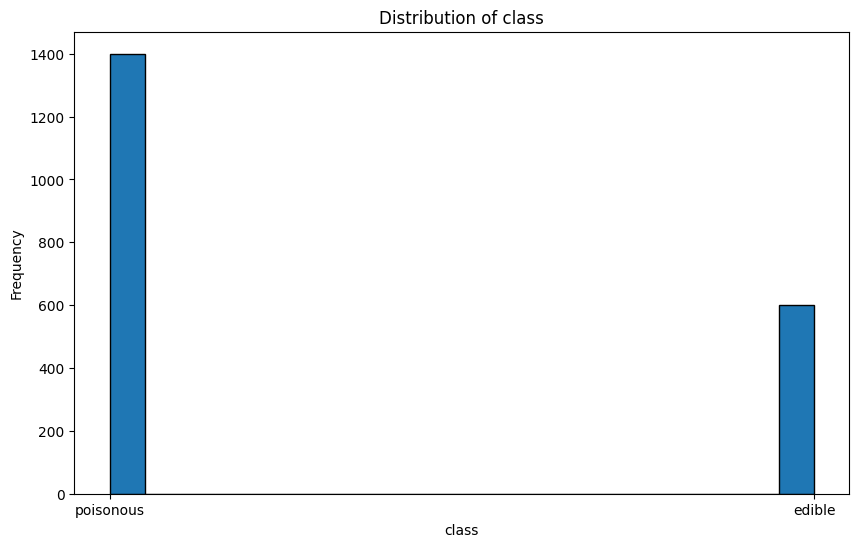

In [4]:
column_to_visualize = 'class'

plt.figure(figsize=(10, 6))
plt.hist(df[column_to_visualize], bins=20, edgecolor='black')
plt.title(f"Distribution of {column_to_visualize}")
plt.xlabel(column_to_visualize)
plt.ylabel("Frequency")
plt.show()

### Encodeing

In [5]:
object_cols = df.select_dtypes(include='object').columns.tolist()
cols_to_encode = [col for col in object_cols if col not in ['Unnamed: 0']]

label_encoders = {}
for col in cols_to_encode:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

display(df.head())

,Unnamed: 0,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat,class,stalk_height,cap_diameter
0,1167,4,2,7,0,1,1,2,0,7,...,0,0,2,6,3,1,5,1,14.276173,5.054983
1,1037,4,0,6,0,1,3,1,1,3,...,1,0,2,6,1,2,5,0,3.952715,19.068319
2,309,3,1,5,1,4,1,1,0,8,...,1,3,2,6,6,0,5,1,9.054265,7.205884
3,282,0,2,4,1,3,3,0,0,6,...,0,3,2,0,4,1,0,1,5.226499,20.932692
4,820,3,3,8,1,5,2,1,1,6,...,1,2,0,4,8,1,4,1,14.037532,12.545245


### Splitting and Scatterplot

In [15]:
X = df.drop('class', axis=1)
Y = df['class']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

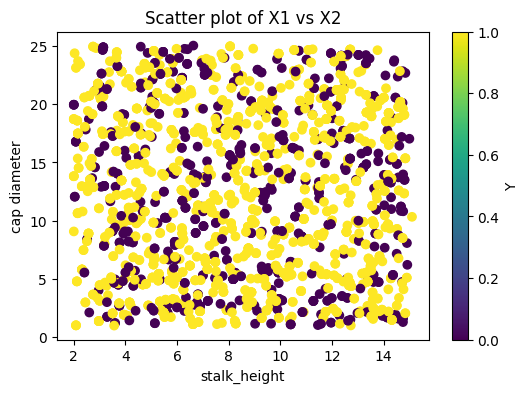

In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(X['stalk_height'], X['cap_diameter'], c=Y, cmap='viridis')
plt.xlabel("stalk_height")
plt.ylabel("cap diameter")
plt.title("Scatter plot of X1 vs X2")
plt.colorbar(label="Y")
plt.show()

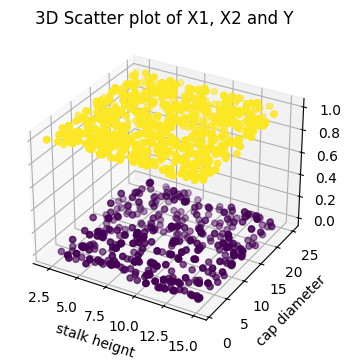

In [8]:
fig = plt.figure(figsize =(6,4))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X['stalk_height'], X['cap_diameter'], Y, c=Y, cmap='viridis')
ax.set_xlabel("stalk heignt")
ax.set_ylabel("cap diameter")
ax.set_zlabel("Y")
ax.set_title("3D Scatter plot of X1, X2 and Y")
plt.show()

### Model fitting

In [16]:
model = SVC(kernel='linear',C=1)
model.fit(X_train, Y_train)
Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

print("Train score =", accuracy_score(Y_train, Y_pred_train))
print("Test score =", accuracy_score(Y_test, Y_pred_test))

Train score = 0.7035714285714286
Test score = 0.6916666666666667


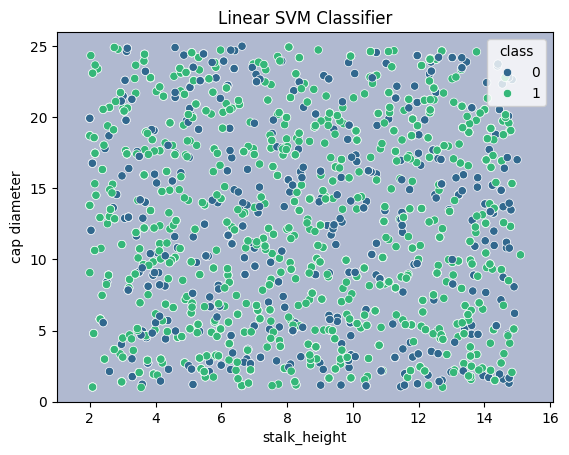

In [ ]:
# X_train, X_test, Y_train, Y_test, model are also assumed to be defined.
X = df[['stalk_height', 'cap_diameter']]
Y = df['class']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)
# Create a meshgrid to visualize the decision boundary
x_min, x_max = X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1
y_min, y_max = X.iloc[:, 1].min() - 1, X.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict the class for each point in the meshgrid
Z = model.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=['stalk_height', 'cap_diameter']))
Z = Z.reshape(xx.shape)

# Plot the decision boundary and the data points
plt.contourf(xx, yy, Z, alpha=0.4)
sns.scatterplot(x=X.iloc[:, 0], y=X.iloc[:, 1], hue=Y, palette="viridis")
plt.xlabel("stalk_height")
plt.ylabel("cap diameter")
plt.title("Linear SVM Classifier")
plt.show()

### matrices

In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate precision, recall, and F1-score for the training set
precision_train = precision_score(Y_train, Y_pred_train)
recall_train = recall_score(Y_train, Y_pred_train)
f1_train = f1_score(Y_train, Y_pred_train)

print("Train Precision:", precision_train)
print("Train Recall:", recall_train)
print("Train F1-score:", f1_train)

# Calculate precision, recall, and F1-score for the test set
precision_test = precision_score(Y_test, Y_pred_test)
recall_test = recall_score(Y_test, Y_pred_test)
f1_test = f1_score(Y_test, Y_pred_test)

print("\nTest Precision:", precision_test)
print("Test Recall:", recall_test)
print("Test F1-score:", f1_test)

Train Precision: 0.7035714285714286
Train Recall: 1.0
Train F1-score: 0.8259958071278826

Test Precision: 0.6916666666666667
Test Recall: 1.0
Test F1-score: 0.8177339901477833


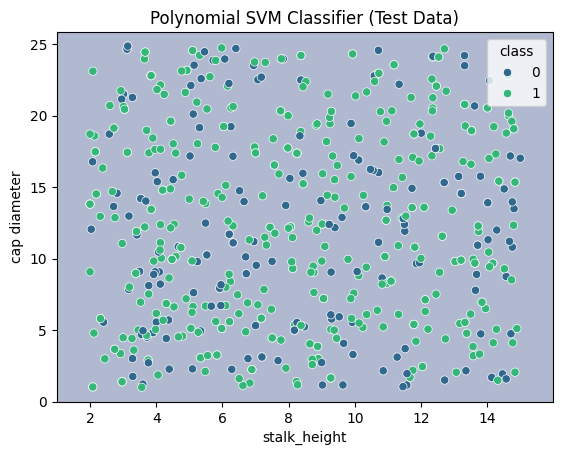

In [25]:

# Create a meshgrid to visualize the decision boundary on the test data
x_min, x_max = X_test.iloc[:, 0].min() - 1, X_test.iloc[:, 0].max() + 1
y_min, y_max = X_test.iloc[:, 1].min() - 1, X_test.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict the class for each point in the meshgrid using the polynomial model
Z = model.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=['stalk_height', 'cap_diameter']))
Z = Z.reshape(xx.shape)

# Plot the decision boundary and the test data points
plt.contourf(xx, yy, Z, alpha=0.4)
sns.scatterplot(x=X_test.iloc[:, 0], y=X_test.iloc[:, 1], hue=Y_test, palette="viridis")
plt.xlabel("stalk_height")
plt.ylabel("cap diameter")
plt.title("Polynomial SVM Classifier (Test Data)")
plt.show()

### Model Fitting Using Different kernel

In [21]:
model = SVC(kernel='poly',degree=3) # degree = 2,3,4
model.fit(X_train, Y_train)
Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

print("Train score =", accuracy_score(Y_train, Y_pred_train))
print("Test score =", accuracy_score(Y_test, Y_pred_test))

Train score = 0.7035714285714286
Test score = 0.6916666666666667


In [23]:
model = SVC(kernel='rbf')
model.fit(X_train, Y_train)
Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

print("Train score =", accuracy_score(Y_train, Y_pred_train))
print("Test score =", accuracy_score(Y_test, Y_pred_test))

Train score = 0.7035714285714286
Test score = 0.6916666666666667


In [26]:
# Calculate and store metrics for each kernel

# Linear kernel metrics (assuming model is the linear kernel model)
linear_train_accuracy = accuracy_score(Y_train, model.predict(X_train))
linear_test_accuracy = accuracy_score(Y_test, model.predict(X_test))
linear_train_precision = precision_score(Y_train, model.predict(X_train))
linear_test_precision = precision_score(Y_test, model.predict(X_test))
linear_train_recall = recall_score(Y_train, model.predict(X_train))
linear_test_recall = recall_score(Y_test, model.predict(X_test))
linear_train_f1 = f1_score(Y_train, model.predict(X_train))
linear_test_f1 = f1_score(Y_test, model.predict(X_test))


# Polynomial kernel metrics (assuming a polynomial model was trained and stored as 'poly_model')
poly_model = SVC(kernel='poly', degree=3)
poly_model.fit(X_train, Y_train)
poly_train_accuracy = accuracy_score(Y_train, poly_model.predict(X_train))
poly_test_accuracy = accuracy_score(Y_test, poly_model.predict(X_test))
poly_train_precision = precision_score(Y_train, poly_model.predict(X_train))
poly_test_precision = precision_score(Y_test, poly_model.predict(X_test))
poly_train_recall = recall_score(Y_train, poly_model.predict(X_train))
poly_test_recall = recall_score(Y_test, poly_model.predict(X_test))
poly_train_f1 = f1_score(Y_train, poly_model.predict(X_train))
poly_test_f1 = f1_score(Y_test, poly_model.predict(X_test))


# RBF kernel metrics (assuming an RBF model was trained and stored as 'rbf_model')
rbf_model = SVC(kernel='rbf')
rbf_model.fit(X_train, Y_train)
rbf_train_accuracy = accuracy_score(Y_train, rbf_model.predict(X_train))
rbf_test_accuracy = accuracy_score(Y_test, rbf_model.predict(X_test))
rbf_train_precision = precision_score(Y_train, rbf_model.predict(X_train))
rbf_test_precision = precision_score(Y_test, rbf_model.predict(X_test))
rbf_train_recall = recall_score(Y_train, rbf_model.predict(X_train))
rbf_test_recall = recall_score(Y_test, rbf_model.predict(X_test))
rbf_train_f1 = f1_score(Y_train, rbf_model.predict(X_train))
rbf_test_f1 = f1_score(Y_test, rbf_model.predict(X_test))


# Create a DataFrame to display the metrics
metrics_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'] * 2,
    'Dataset': ['Train'] * 4 + ['Test'] * 4,
    'Linear Kernel': [linear_train_accuracy, linear_train_precision, linear_train_recall, linear_train_f1,
                      linear_test_accuracy, linear_test_precision, linear_test_recall, linear_test_f1],
    'Polynomial Kernel (degree=3)': [poly_train_accuracy, poly_train_precision, poly_train_recall, poly_train_f1,
                                      poly_test_accuracy, poly_test_precision, poly_test_recall, poly_test_f1],
    'RBF Kernel': [rbf_train_accuracy, rbf_train_precision, rbf_train_recall, rbf_train_f1,
                   rbf_test_accuracy, rbf_test_precision, rbf_test_recall, rbf_test_f1]
}

metrics_df = pd.DataFrame(metrics_data)
display(metrics_df)

,Metric,Dataset,Linear Kernel,Polynomial Kernel (degree=3),RBF Kernel
0,Accuracy,Train,0.703571,0.703571,0.703571
1,Precision,Train,0.703571,0.703571,0.703571
2,Recall,Train,1.000000,1.000000,1.000000
3,F1-score,Train,0.825996,0.825996,0.825996
4,Accuracy,Test,0.691667,0.691667,0.691667
5,Precision,Test,0.691667,0.691667,0.691667
6,Recall,Test,1.000000,1.000000,1.000000
7,F1-score,Test,0.817734,0.817734,0.817734


**Analysis of SVM Strengths and Weaknesses for the Mushroom Dataset**

Based on the EDA and visualization results, we can observe the following regarding the SVM performance:

**Strengths:**

* **Ability to Handle Non-Linearity (with different kernels):** While the linear kernel didn't show a significant improvement over a simple linear separation. If the data had a more complex, non-linear separation, these kernels would likely be more beneficial.
* **Relatively Good Recall:** The recall score is high across all kernels, indicating that the model is good at identifying most of the positive cases (edible mushrooms). This is important in a scenario where failing to identify an edible mushroom is less critical than misclassifying a poisonous one as edible.

**Weaknesses:**

* **Limited Improvement with Complex Kernels:** The performance metrics (accuracy, precision, F1-score) are very similar across all kernels, and the decision boundaries in the visualizations appear quite linear. This suggests that the relationship between `stalk_height` and `cap_diameter` and the class is likely close to linear, and the more complex kernels (polynomial and RBF) are not providing a significant advantage.
* **Moderate Precision:** The precision scores are lower than the recall scores. This means that when the model predicts a mushroom is edible, it is not always correct (it has a higher rate of false positives).
* **Data Separability:** The scatter plots show a significant overlap between the two classes based on `stalk_height` and `cap_diameter`.
* **Potential Dependence on Feature Engineering:** The limited performance using only `stalk_height` and `cap_diameter` suggests that other features in the dataset might be more informative for classification.

**Practical Implications of SVM in Real-World Classification Tasks**

SVMs are powerful and versatile algorithms for classification, with several practical implications:

**Strengths in Real-World Scenarios:**

*   **Effective in High-Dimensional Spaces:** SVMs perform well in datasets with a large number of features, which is common in areas like text classification, image recognition, and bioinformatics.
*   **Memory Efficient:** Since SVMs only use a subset of the training data (support vectors) to define the decision boundary, they are more memory efficient compared to some other algorithms that might need to store the entire dataset.
*   **Versatile Kernel Options:** The availability of different kernel functions allows SVMs to handle various types of data and complex decision boundaries.
*   **Robustness to Outliers:** SVMs are relatively robust to outliers, especially when using the soft margin concept (allowing for some misclassifications) because the decision boundary is primarily influenced by the support vectors, not all data points.

**Weaknesses and Considerations in Real-World Scenarios:**

*   **Performance on Large Datasets:** Training can be computationally expensive, especially on large datasets. The training time can increase significantly with the number of training examples.
*   **Choice of Kernel and Parameters:** Selecting the appropriate kernel function and tuning parameters (like C and gamma) can be challenging and often requires experimentation and cross-validation. Poor choices can lead to suboptimal performance.
*   **Lack of Probability Estimates:** Standard SVM outputs are class labels, not probability estimates. While extensions exist to provide probabilities, they can add complexity. For applications requiring probability scores (e.g., risk assessment), other algorithms might be more straightforward.
*   **Interpretability:** Understanding the decision boundary and the influence of individual features in SVMs, especially with non-linear kernels, can be less intuitive compared to models like decision trees.
*   **Binary Classification Primarily:** While SVMs can be extended to multi-class problems, they are inherently designed for binary classification. Implementing multi-class SVMs typically involves strategies like one-vs-one or one-vs-rest, which can increase complexity and training time.